## A cycle of reactions between `A`, `B` and `C` :  (1) `A <-> B <-> C `
#### the "closing" of the above cycle (the "return" path from `C` to `A`) is coupled with an "energy donor" reaction:
## (2) `C + E_High <-> A + E_Low`
#### where `E_High` and `E_Low` are, respectively, the high- and low- energy molecules that drive the cycle (for example, think of ATP/ADP).   
Comparisons are made between results obtained with 3 different time resolutions.

All 1st-order kinetics <- *This is just an exploration of the software; not meant to be realistic!*  

LAST REVISED: June 23, 2024 (using v. 1.0 beta36)

In [1]:
import set_path      # Importing this module will add the project's home directory to sys.path

Added 'D:\Docs\- MY CODE\BioSimulations\life123-Win7' to sys.path


In [2]:
from experiments.get_notebook_info import get_notebook_basename

from life123 import ChemData
from life123 import UniformCompartment
from life123 import Numerical as num

from life123 import GraphicLog

In [3]:
# Initialize the HTML logging
log_file = get_notebook_basename() + ".log.htm"    # Use the notebook base filename for the log file

# Set up the use of some specified graphic (Vue) components
GraphicLog.config(filename=log_file,
                  components=["vue_cytoscape_2"],
                  extra_js="https://cdnjs.cloudflare.com/ajax/libs/cytoscape/3.21.2/cytoscape.umd.js")

-> Output will be LOGGED into the file 'cycles_1.log.htm'


### Initialize the system

In [4]:
# Initialize the system
chem_data = ChemData(names=["A", "B", "C", "E_high", "E_low"])

# Reaction A <-> B, mostly in forward direction (favored energetically)
# Note: all reactions in this experiment have 1st-order kinetics for all species
chem_data.add_reaction(reactants="A", products="B",
                       forward_rate=9., reverse_rate=3.)

# Reaction B <-> C, also favored energetically
chem_data.add_reaction(reactants="B", products="C",
                       forward_rate=8., reverse_rate=4.)

# Reaction C + E_High <-> A + E_Low, also favored energetically, but kinetically slow
# Note that, thanks to the energy donation from E, we can go "upstream" from C, to the higher-energy level of "A"
chem_data.add_reaction(reactants=["C" , "E_high"], products=["A", "E_low"],
                       forward_rate=1., reverse_rate=0.2)

chem_data.describe_reactions()

# Send the plot of the reaction network to the HTML log file
chem_data.plot_reaction_network("vue_cytoscape_2")

Number of reactions: 3 (at temp. 25 C)
0: A <-> B  (kF = 9 / kR = 3 / delta_G = -2,723.4 / K = 3) | 1st order in all reactants & products
1: B <-> C  (kF = 8 / kR = 4 / delta_G = -1,718.3 / K = 2) | 1st order in all reactants & products
2: C + E_high <-> A + E_low  (kF = 1 / kR = 0.2 / delta_G = -3,989.7 / K = 5) | 1st order in all reactants & products
Set of chemicals involved in the above reactions: {'E_high', 'C', 'B', 'E_low', 'A'}
[GRAPHIC ELEMENT SENT TO LOG FILE `cycles_1.log.htm`]


### Set the initial concentrations of all the chemicals

In [5]:
initial_conc = {"A": 100., "E_high": 1000.}  # Note the abundant energy source "E_high"; anything not specified will default to zero
initial_conc

{'A': 100.0, 'E_high': 1000.0}

# Run # 1 : FIXED time resolution, with COARSE time steps - broken up in 3 time intervals    
(trial and error, not shown, reveals that increasing any of the time steps below, leads to "excessive time step" errors;  
note: fixed time resolution is generelly NOT recommended, except for double-checks and error analysis)

In [6]:
dynamics = UniformCompartment(chem_data=chem_data)
dynamics.set_conc(conc=initial_conc, snapshot=True)
dynamics.describe_state()

SYSTEM STATE at Time t = 0:
5 species:
  Species 0 (A). Conc: 100.0
  Species 1 (B). Conc: 0.0
  Species 2 (C). Conc: 0.0
  Species 3 (E_high). Conc: 1000.0
  Species 4 (E_low). Conc: 0.0
Set of chemicals involved in reactions: {'E_high', 'C', 'B', 'E_low', 'A'}


In [7]:
dynamics.enable_diagnostics()       # To save diagnostic information about the call to single_compartment_react()

### We'll split the simulation in three segments (apparent from the graphs of the runs, further down):  
Time [0-0.03] fast changes   
Time [0.03-5.] medium changes   
Time [5.-8.] slow changes, as we approach equilibrium  

In [8]:
dynamics.single_compartment_react(initial_step=0.0008, target_end_time=0.03, variable_steps=False)
#dynamics.get_history()

38 total step(s) taken


In [9]:
dynamics.single_compartment_react(initial_step=0.001, target_end_time=5., variable_steps=False)
#dynamics.get_history()

4970 total step(s) taken


In [10]:
dynamics.single_compartment_react(initial_step=0.005, target_end_time=8., variable_steps=False)

600 total step(s) taken


In [11]:
dynamics.get_history()

,SYSTEM TIME,A,B,C,E_high,E_low,caption
0,0.0000,100.000000,0.000000,0.000000,1000.000000,0.000000,Initialized state
1,0.0008,99.280000,0.720000,0.000000,1000.000000,0.000000,
2,0.0016,98.566912,1.428480,0.004608,1000.000000,0.000000,
3,0.0024,97.864345,2.125606,0.010049,999.996314,0.003686,
4,0.0032,97.172805,2.811556,0.015639,999.988332,0.011668,
...,...,...,...,...,...,...,...
5604,7.9804,10.018545,30.006917,59.974537,32.331113,967.668887,
5605,7.9854,10.018398,30.006862,59.974740,32.330530,967.669470,
5606,7.9904,10.018251,30.006808,59.974942,32.329952,967.670048,
5607,7.9954,10.018105,30.006753,59.975142,32.329378,967.670622,


### Notice we created 5,609 data points, in 3 hand-picked segments at different time resolutions

In [12]:
dynamics.explain_time_advance()

From time 0 to 0.0304, in 38 steps of 0.0008
From time 0.0304 to 5, in 4970 steps of 0.001
From time 5 to 8, in 600 steps of 0.005
(5608 steps total)


## Plots of changes of concentration with time

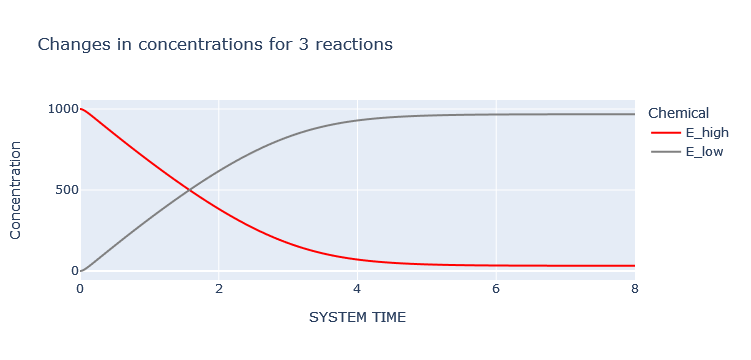

In [13]:
dynamics.plot_history(chemicals=["E_high", "E_low"], colors=["red", "grey"])

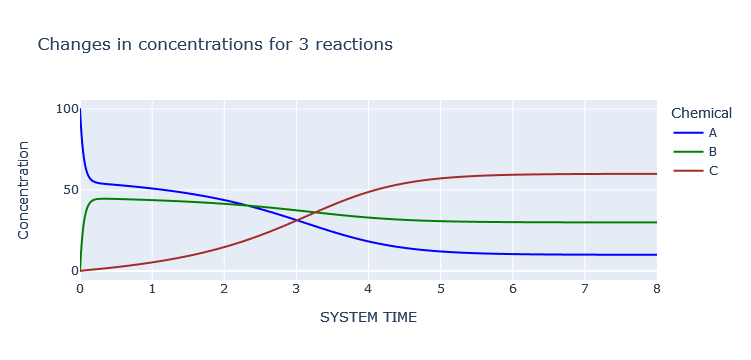

In [14]:
dynamics.plot_history(chemicals=["A", "B", "C"])

### The plots has 4 distinctive intersections; locate them and save them for later comparisons across repeated runs:

In [15]:
run1 = []

In [16]:
run1.append(dynamics.curve_intersect("E_high", "E_low", t_start=1., t_end=2.))

In [17]:
run1.append(dynamics.curve_intersect("A", "B", t_start=2.31, t_end=2.33))

In [18]:
run1.append(dynamics.curve_intersect("A", "C", t_start=3., t_end=4.))

In [19]:
run1.append(dynamics.curve_intersect("B", "C", t_start=3., t_end=4.))

In [20]:
run1

[(1.5782463316015305, 499.9999999999999),
 (2.324208426199163, 40.36968965779538),
 (3.0098252303164066, 31.29187589510951),
 (3.2624567026161637, 36.1939052299051)]

### Verify the final equilibrium state:

In [21]:
dynamics.is_in_equilibrium()

0: A <-> B
Final concentrations: [A] = 10.02 ; [B] = 30.01
1. Ratio of reactant/product concentrations, adjusted for reaction orders: 2.99529
    Formula used:  [B] / [A]
2. Ratio of forward/reverse reaction rates: 3
Discrepancy between the two values: 0.157 %
Reaction IS in equilibrium (within 1% tolerance)

1: B <-> C
Final concentrations: [B] = 30.01 ; [C] = 59.98
1. Ratio of reactant/product concentrations, adjusted for reaction orders: 1.99873
    Formula used:  [C] / [B]
2. Ratio of forward/reverse reaction rates: 2
Discrepancy between the two values: 0.06342 %
Reaction IS in equilibrium (within 1% tolerance)

2: C + E_high <-> A + E_low
Final concentrations: [C] = 59.98 ; [E_high] = 32.33 ; [A] = 10.02 ; [E_low] = 967.7
1. Ratio of reactant/product concentrations, adjusted for reaction orders: 4.99971
    Formula used:  ([A][E_low]) / ([C][E_high])
2. Ratio of forward/reverse reaction rates: 5
Discrepancy between the two values: 0.005823 %
Reaction IS in equilibrium (within 1% t

True

# _NOTE: Everything below, to the end, is JUST A REPEAT of the same experiment, with different time steps, for accuracy comparisons_

# Run # 2. VARIABLE time resolution

In [22]:
dynamics = UniformCompartment(chem_data=chem_data, preset="mid_inclusive")   # Note: OVER-WRITING the "dynamics" object  # heavy_brakes
dynamics.set_conc(conc=initial_conc, snapshot=True) 
dynamics.describe_state()

SYSTEM STATE at Time t = 0:
5 species:
  Species 0 (A). Conc: 100.0
  Species 1 (B). Conc: 0.0
  Species 2 (C). Conc: 0.0
  Species 3 (E_high). Conc: 1000.0
  Species 4 (E_low). Conc: 0.0
Set of chemicals involved in reactions: {'E_high', 'C', 'B', 'E_low', 'A'}


In [23]:
# These will affect the dynamic automated choices of time steps, 
# and were specified by the preset used in instantiating the "dynamics" object
dynamics.show_adaptive_parameters()  

Parameters used for the automated adaptive time step sizes -
    THRESHOLDS:  [{'norm': 'norm_A', 'low': 0.2, 'high': 0.8, 'abort': 1.44}, {'norm': 'norm_B', 'low': 0.08, 'high': 0.5, 'abort': 1.5}, {'norm': 'norm_C', 'low': 0.5, 'high': 1.2, 'abort': 1.6}, {'norm': 'norm_D', 'low': 1.3, 'high': 1.7, 'abort': 1.8}]
    STEP FACTORS:  {'upshift': 1.1, 'downshift': 0.5, 'abort': 0.4, 'error': 0.25}


In [24]:
dynamics.enable_diagnostics()       # To save diagnostic information about the call to single_compartment_react()

In [25]:
dynamics.single_compartment_react(initial_step=0.0001, target_end_time=8.0,
                                  variable_steps=True, explain_variable_steps=None)

1911 total step(s) taken
Number of step re-do's because of negative concentrations: 16
Number of step re-do's because of elective soft aborts: 114
Norm usage: {'norm_A': 1533, 'norm_B': 1536, 'norm_C': 1620, 'norm_D': 1577}


### Notice we created 1,911 data points, a good deal less than in run #1

In [26]:
dynamics.get_history()

,SYSTEM TIME,A,B,C,E_high,E_low,caption
0,0.000000,100.000000,0.000000,0.000000,1000.000000,0.000000,Initialized state
1,0.000100,99.910000,0.090000,0.000000,1000.000000,0.000000,
2,0.000210,99.811119,0.188802,0.000079,1000.000000,0.000000,
3,0.000265,99.761748,0.238094,0.000158,999.999996,0.000004,
4,0.000293,99.737081,0.262713,0.000206,999.999991,0.000009,
...,...,...,...,...,...,...,...
1907,7.920378,10.018699,30.006975,59.974327,32.331717,967.668283,
1908,7.939029,10.018143,30.006767,59.975090,32.329524,967.670476,
1909,7.959545,10.017545,30.006546,59.975909,32.327188,967.672812,
1910,7.982112,10.016934,30.006310,59.976756,32.324679,967.675321,


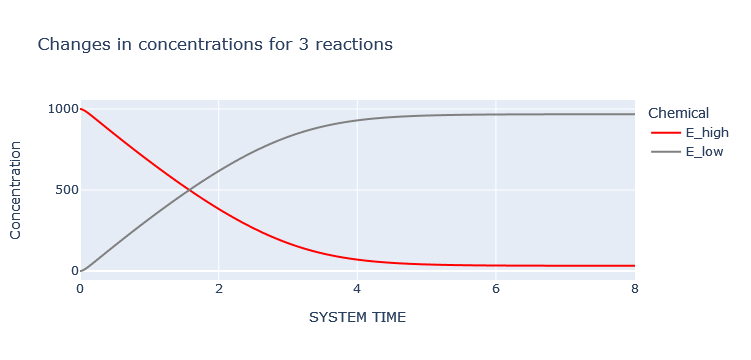

In [27]:
dynamics.plot_history(chemicals=["E_high", "E_low"], colors=["red", "grey"])

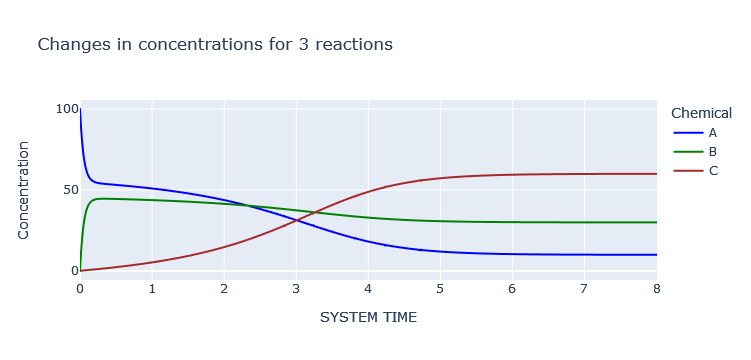

In [28]:
dynamics.plot_history(chemicals=["A", "B", "C"])

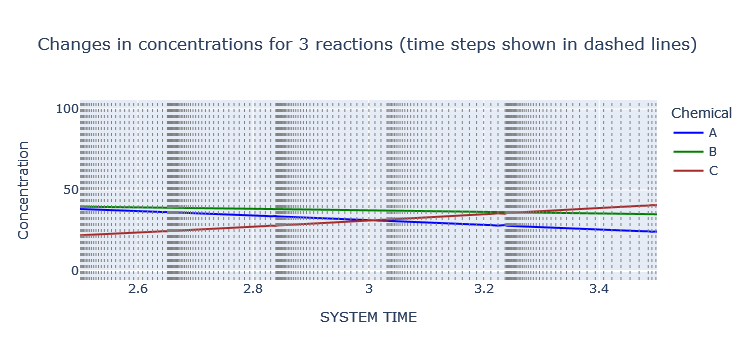

In [29]:
# Show the timestepe taken (vertical dashed lines) in a small section of the plot
dynamics.plot_history(chemicals=["A", "B", "C"], show_intervals=True, range_x=[2.5, 3.5])

In [30]:
dynamics.explain_time_advance()  # Notice a lot of timestep adjustments, as needed

From time 0 to 0.0001, in 1 step of 0.0001
From time 0.0001 to 0.00021, in 1 step of 0.00011
From time 0.00021 to 0.000265, in 1 step of 5.5e-05
From time 0.000265 to 0.0002925, in 1 step of 2.75e-05
From time 0.0002925 to 0.0006087, in 23 steps of 1.37e-05
From time 0.0006087 to 0.0006541, in 3 steps of 1.51e-05
From time 0.0006541 to 0.000704, in 3 steps of 1.66e-05
From time 0.000704 to 0.0007589, in 3 steps of 1.83e-05
From time 0.0007589 to 0.0008193, in 3 steps of 2.01e-05
From time 0.0008193 to 0.0008858, in 3 steps of 2.21e-05
From time 0.0008858 to 0.0009588, in 3 steps of 2.44e-05
From time 0.0009588 to 0.001039, in 3 steps of 2.68e-05
From time 0.001039 to 0.001128, in 3 steps of 2.95e-05
From time 0.001128 to 0.001225, in 3 steps of 3.24e-05
From time 0.001225 to 0.001332, in 3 steps of 3.57e-05
From time 0.001332 to 0.00145, in 3 steps of 3.92e-05
From time 0.00145 to 0.001579, in 3 steps of 4.32e-05
From time 0.001579 to 0.001721, in 3 steps of 4.75e-05
From time 0.001721

### Just like we saw in the earlier run, the two plots have 4 distinctive intersections among them; locate and save them:

In [31]:
run2 = []

In [32]:
run2.append(dynamics.curve_intersect(t_start=1., t_end=2., chem1="E_high", chem2="E_low"))  # This can be seen in the 1st plot

In [33]:
run2.append(dynamics.curve_intersect(t_start=2.31, t_end=2.33, chem1="A", chem2="B"))       # This, and later, can be seen in the 2nd plot

In [34]:
run2.append(dynamics.curve_intersect(t_start=3., t_end=4., chem1="A", chem2="C"))

In [35]:
run2.append(dynamics.curve_intersect(t_start=3., t_end=4., chem1="B", chem2="C"))

In [36]:
run2

[(1.5780067649840679, 499.999999999999),
 (2.3232195286058, 40.37131994241191),
 (3.0085519261791998, 31.292420179037926),
 (3.260088742083356, 36.19449057022661)]

# Run # 3. FIXED time resolution, using FINER fixed resolution than in run #1 

In [37]:
dynamics = UniformCompartment(chem_data=chem_data)   # Note: OVER-WRITING the "dynamics" object
dynamics.set_conc(conc=initial_conc, snapshot=True) 
dynamics.describe_state()

SYSTEM STATE at Time t = 0:
5 species:
  Species 0 (A). Conc: 100.0
  Species 1 (B). Conc: 0.0
  Species 2 (C). Conc: 0.0
  Species 3 (E_high). Conc: 1000.0
  Species 4 (E_low). Conc: 0.0
Set of chemicals involved in reactions: {'E_high', 'C', 'B', 'E_low', 'A'}


In [38]:
dynamics.enable_diagnostics()       # To save diagnostic information about the call to single_compartment_react()

In [39]:
dynamics.single_compartment_react(initial_step=0.0004, target_end_time=0.03, variable_steps=False)

75 total step(s) taken


In [40]:
dynamics.single_compartment_react(initial_step=0.0005, target_end_time=5., variable_steps=False)

9940 total step(s) taken


In [41]:
dynamics.single_compartment_react(initial_step=0.0025, target_end_time=8., variable_steps=False)

1200 total step(s) taken


In [42]:
dynamics.get_history()

,SYSTEM TIME,A,B,C,E_high,E_low,caption
0,0.0000,100.000000,0.000000,0.000000,1000.000000,0.000000,Initialized state
1,0.0004,99.640000,0.360000,0.000000,1000.000000,0.000000,
2,0.0008,99.281728,0.717120,0.001152,1000.000000,0.000000,
3,0.0012,98.925635,1.071381,0.002984,999.999539,0.000461,
4,0.0016,98.571979,1.422804,0.005218,999.998349,0.001651,
...,...,...,...,...,...,...,...
11211,7.9900,10.018459,30.006885,59.974656,32.330771,967.669229,
11212,7.9925,10.018385,30.006858,59.974757,32.330481,967.669519,
11213,7.9950,10.018312,30.006830,59.974858,32.330192,967.669808,
11214,7.9975,10.018239,30.006803,59.974958,32.329904,967.670096,


### Notice we created 11,215 data points, A LOT MORE than in runs #1 and #2

In [43]:
dynamics.explain_time_advance()

From time 0 to 0.03, in 75 steps of 0.0004
From time 0.03 to 5, in 9940 steps of 0.0005
From time 5 to 8, in 1200 steps of 0.0025
(11215 steps total)


## Plots of changes of concentration with time

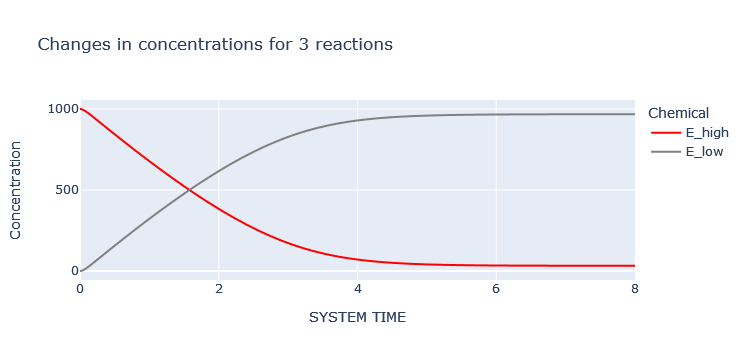

In [44]:
dynamics.plot_history(chemicals=["E_high", "E_low"], colors=["red", "grey"])

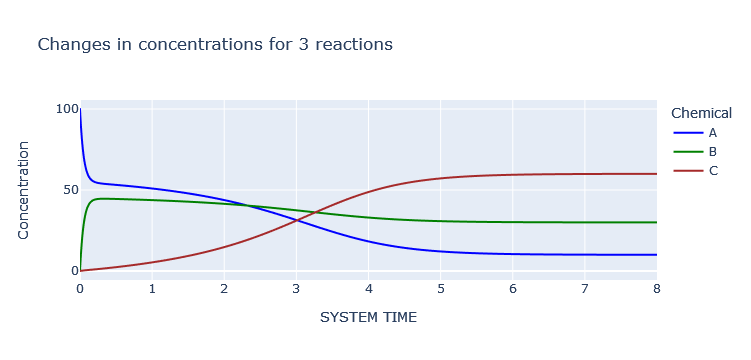

In [45]:
dynamics.plot_history(chemicals=["A", "B", "C"])

### Yet again, the two plots have 4 distinctive intersections among them; locate and save them:

In [46]:
run3 = []

In [47]:
run3.append(dynamics.curve_intersect(t_start=1., t_end=2., chem1="E_high", chem2="E_low"))

In [48]:
run3.append(dynamics.curve_intersect(t_start=2.31, t_end=2.33, chem1="A", chem2="B"))

In [49]:
run3.append(dynamics.curve_intersect(t_start=3., t_end=4., chem1="A", chem2="C"))

In [50]:
run3.append(dynamics.curve_intersect(t_start=3., t_end=4., chem1="B", chem2="C"))

In [51]:
run3

[(1.5782924165400347, 500.00000000000097),
 (2.324314772661154, 40.369610560733825),
 (3.0100101552808494, 31.29190450449909),
 (3.262685299694276, 36.193867736703666)]

# Finally, compare (using a Euclidean metric) the discrepancy between the runs
Run #3, at high resolution, could be thought of as "the closest to the actual values"

In [52]:
# Discrepancy of run1 from run3
num.compare_results(run1, run3)

0.00032919271043321753

In [53]:
# Discrepancy of run2 from run3
num.compare_results(run2, run3)

0.0037047978947051976

Run 2 (with a lot fewer points than run 1), not surprisingly deviates a bit more from the (presumably) highly-accurate run 3

#### The coordinates of the 4 critical points, from the 3 different runs, are pretty similar to one another - as can be easily seen:

In [54]:
run1

[(1.5782463316015305, 499.9999999999999),
 (2.324208426199163, 40.36968965779538),
 (3.0098252303164066, 31.29187589510951),
 (3.2624567026161637, 36.1939052299051)]

In [55]:
run2

[(1.5780067649840679, 499.999999999999),
 (2.3232195286058, 40.37131994241191),
 (3.0085519261791998, 31.292420179037926),
 (3.260088742083356, 36.19449057022661)]

In [56]:
run3

[(1.5782924165400347, 500.00000000000097),
 (2.324314772661154, 40.369610560733825),
 (3.0100101552808494, 31.29190450449909),
 (3.262685299694276, 36.193867736703666)]